# Customer Segmentation using K-Means Clustering
## Mall Customer Segmentation Dataset

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

## 1. Load and Explore Data

In [2]:
# Download dataset from Kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

# Read the CSV file
import os
csv_file = os.path.join(path, 'Mall_Customers.csv')
df = pd.read_csv(csv_file)

# Display basic info
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

100%|██████████| 1.55k/1.55k [00:00<00:00, 737kB/s]

Extracting files...


Dataset Shape: (200, 5)

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
df.describe()

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 2. Data Preprocessing

In [4]:
# Select features for clustering
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features shape:", X_scaled.shape)

Features shape: (200, 2)


## 3. Determine Optimal Number of Clusters

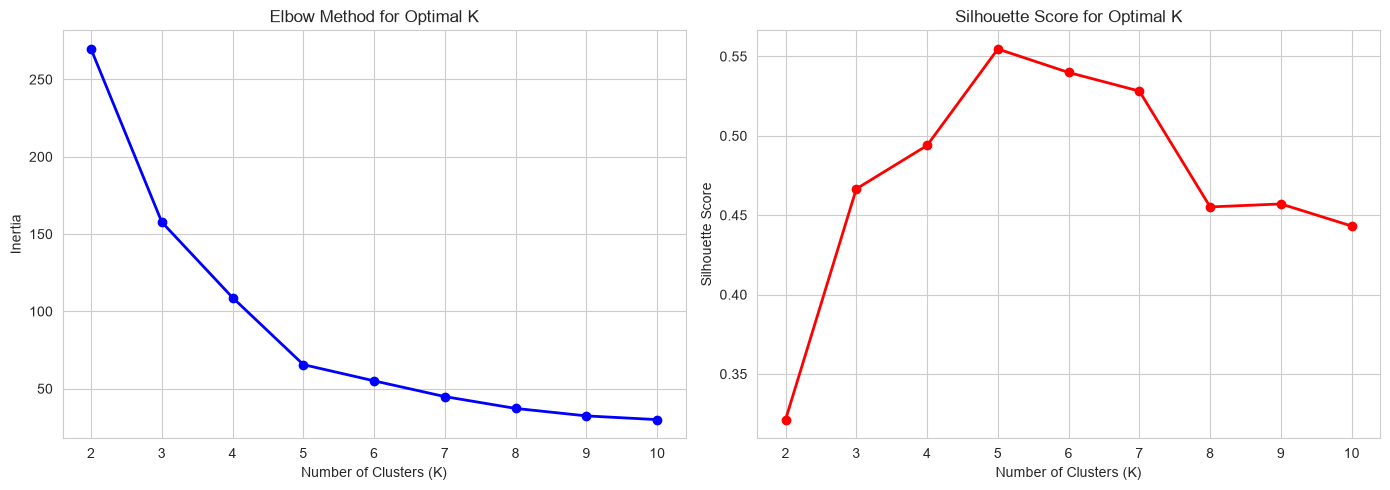

Best Silhouette Score: 0.555 at K=5


In [5]:
# Elbow Method
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Plot Elbow
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(K_range, inertias, 'bo-', linewidth=2)
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method for Optimal K')
ax1.grid(True)

ax2.plot(K_range, silhouette_scores, 'ro-', linewidth=2)
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Score for Optimal K')
ax2.grid(True)

plt.tight_layout()
plt.show()

print(f"Best Silhouette Score: {max(silhouette_scores):.3f} at K={K_range[np.argmax(silhouette_scores)]}")

## 4. Apply K-Means with Optimal K

In [6]:
# Choose optimal K (let's use 5 as it's common for this dataset)
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to original dataframe
df['Cluster'] = clusters

print("Cluster Distribution:")
print(df['Cluster'].value_counts().sort_index())

Cluster Distribution:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


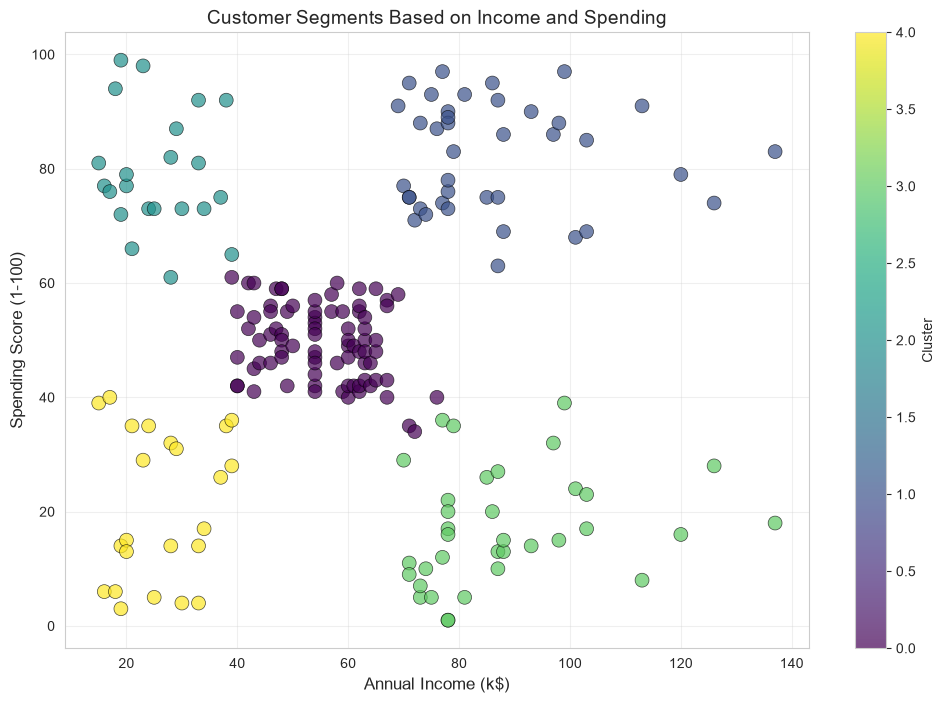

In [7]:
# Visualize clusters in original 2D space
plt.figure(figsize=(12, 8))

scatter = plt.scatter(df['Annual Income (k$)'], 
                     df['Spending Score (1-100)'],
                     c=df['Cluster'], 
                     cmap='viridis', 
                     s=100, 
                     alpha=0.7,
                     edgecolors='black',
                     linewidth=0.5)

plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.title('Customer Segments Based on Income and Spending', fontsize=14)
plt.colorbar(scatter, label='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

## 5. PCA for Dimensionality Reduction

Explained Variance Ratio: [0.50495142 0.49504858]
Total Variance Explained: 100.00%


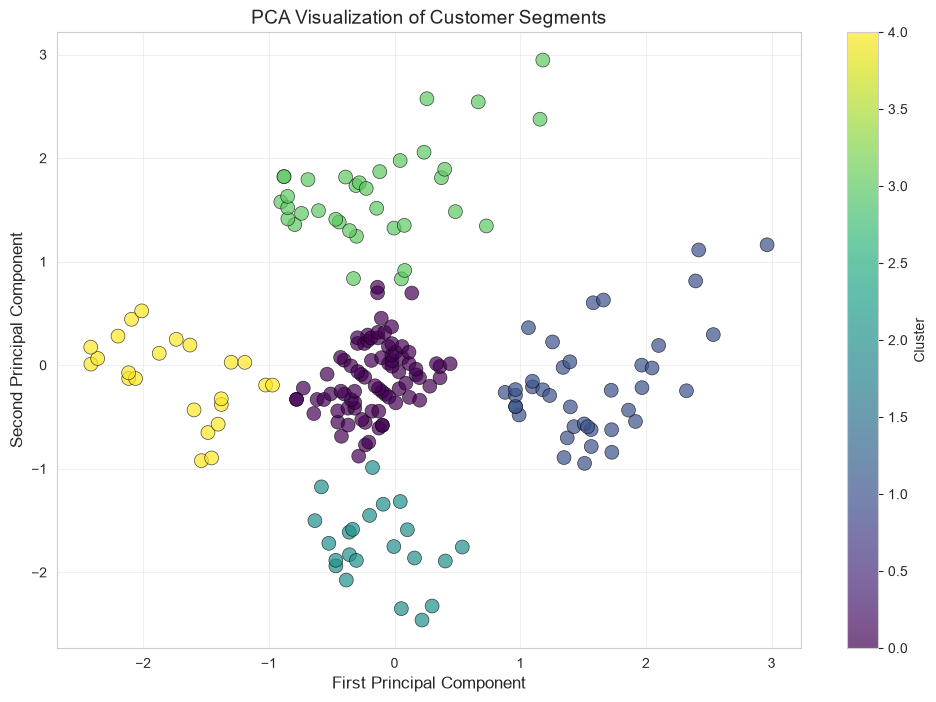

In [8]:
# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Add PCA components to dataframe
df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

# Explained variance
print(f"Explained Variance Ratio: {pca.explained_variance_ratio_}")
print(f"Total Variance Explained: {sum(pca.explained_variance_ratio_):.2%}")

# Visualize PCA
plt.figure(figsize=(12, 8))

scatter = plt.scatter(df['PCA1'], df['PCA2'], 
                     c=df['Cluster'], 
                     cmap='viridis', 
                     s=100, 
                     alpha=0.7,
                     edgecolors='black',
                     linewidth=0.5)

plt.xlabel('First Principal Component', fontsize=12)
plt.ylabel('Second Principal Component', fontsize=12)
plt.title('PCA Visualization of Customer Segments', fontsize=14)
plt.colorbar(scatter, label='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

## 6. Cluster Analysis

In [9]:
# Analyze cluster characteristics
cluster_analysis = df.groupby('Cluster').agg({
    'Annual Income (k$)': ['mean', 'std', 'min', 'max'],
    'Spending Score (1-100)': ['mean', 'std', 'min', 'max'],
    'Age': ['mean', 'std', 'min', 'max']
}).round(2)

print("Cluster Characteristics:")
cluster_analysis

Cluster Characteristics:


Annual Income (k$)                 Spending Score (1-100)             \
                      mean    std min  max                   mean    std min   
Cluster                                                                        
0                    55.30   8.99  39   76                  49.52   6.53  34   
1                    86.54  16.31  69  137                  82.13   9.36  63   
2                    25.73   7.57  15   39                  79.36  10.50  61   
3                    88.20  16.40  70  137                  17.11   9.95   1   
4                    26.30   7.89  15   39                  20.91  13.02   3   

               Age                 
        max   mean    std min max  
Cluster                            
0        61  42.72  16.45  18  70  
1        97  32.69   3.73  27  40  
2        99  25.27   5.26  18  35  
3        39  41.11  11.34  19  59  
4        40  45.22  13.23  19  67

In [10]:
# Distribution of gender across clusters
gender_dist = pd.crosstab(df['Cluster'], df['Gender'], normalize='index')
print("\nGender Distribution by Cluster:")
gender_dist


Gender Distribution by Cluster:


Gender,Female,Male
Cluster,,
0,0.592593,0.407407
1,0.538462,0.461538
2,0.590909,0.409091
3,0.457143,0.542857
4,0.608696,0.391304


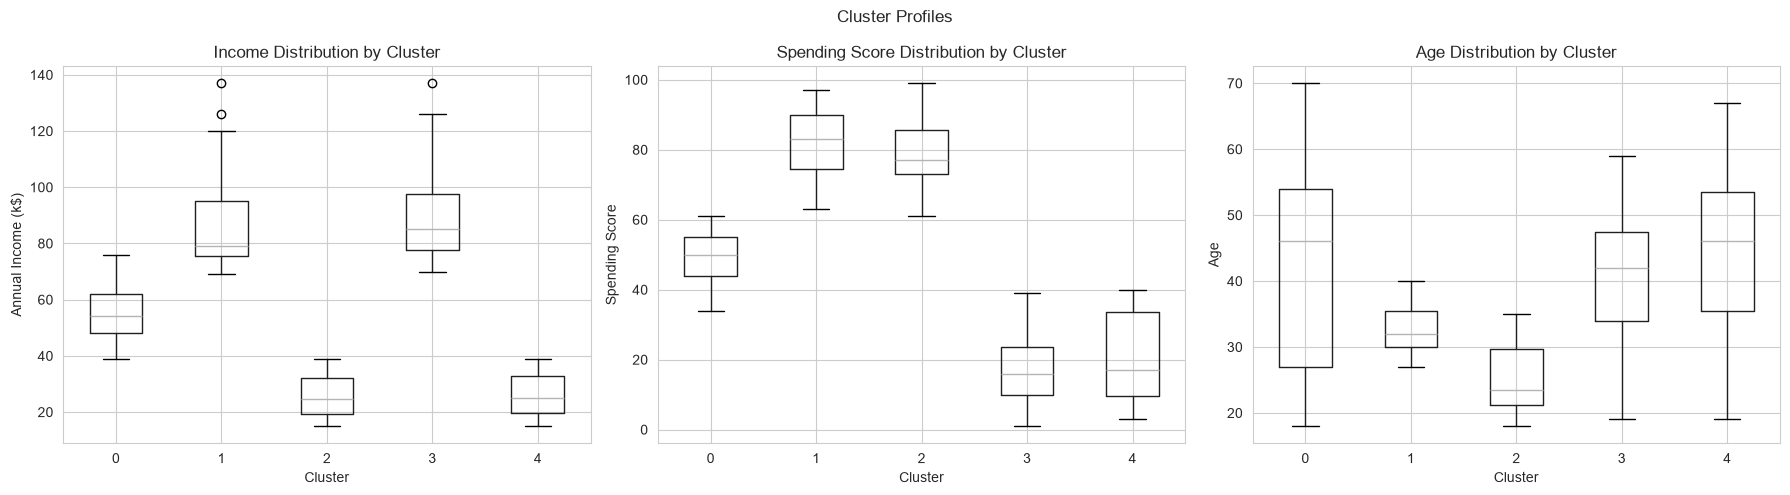

In [11]:
# Visualize cluster profiles
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Income distribution by cluster
df.boxplot(column='Annual Income (k$)', by='Cluster', ax=axes[0])
axes[0].set_title('Income Distribution by Cluster')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Annual Income (k$)')

# Spending distribution by cluster
df.boxplot(column='Spending Score (1-100)', by='Cluster', ax=axes[1])
axes[1].set_title('Spending Score Distribution by Cluster')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Spending Score')

# Age distribution by cluster
df.boxplot(column='Age', by='Cluster', ax=axes[2])
axes[2].set_title('Age Distribution by Cluster')
axes[2].set_xlabel('Cluster')
axes[2].set_ylabel('Age')

plt.suptitle('Cluster Profiles')
plt.tight_layout()
plt.show()

## 7. Save Models

In [12]:
import joblib
import os

# Create models directory if it doesn't exist
if not os.path.exists('../models'):
    os.makedirs('../models')

# Save models
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(kmeans, '../models/kmeans_model.pkl')
joblib.dump(pca, '../models/pca_model.pkl')

# Save cluster centers for reference
cluster_centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features
)
cluster_centers.to_csv('../models/cluster_centers.csv', index=False)

print("Models saved successfully!")
print("Cluster Centers:")
cluster_centers

Models saved successfully!
Cluster Centers:


,Annual Income (k$),Spending Score (1-100)
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


## 8. Summary

### Key Findings:
1. **Optimal Number of Clusters**: 5 clusters identified
2. **Customer Segments**:
   - High Income, High Spending
   - High Income, Low Spending
   - Average Income, Average Spending
   - Low Income, Low Spending
   - Low Income, High Spending
3. **Business Insights**:
   - Target high-value customers with premium offers
   - Re-engage high-income but low-spending customers
   - Develop loyalty programs for loyal customers
   - Focus marketing on high-potential segments